In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull

from pydrake.geometry.optimization import HPolyhedron
from pydrake.solvers import MosekSolver

from gcs.bezier import BezierGCS
from gcs.linear import LinearGCS
from models.env_2d import obstacles, vertices

savefig = 0

# Environment setup

In [2]:
x_start = np.array([.2, .2])
x_goal = np.array([4.8, 4.8])

x_min = np.min(np.vstack(vertices), axis=0)
x_max = np.max(np.vstack(vertices), axis=0)

def make_hpolytope(V):
    ch = ConvexHull(V)
    return HPolyhedron(ch.equations[:, :-1], - ch.equations[:, -1])

regions = [make_hpolytope(V) for V in vertices]

def environment_setup():
    
    plt.figure(figsize=(3, 3))
    plt.axis('square')
    
    plt.xlim([x_min[0], x_max[0]])
    plt.ylim([x_min[1], x_max[1]])
    
    tick_gap = .2
    n_ticks = lambda x_min, x_max: round((x_max - x_min) / tick_gap) + 1
    x_ticks = np.linspace(x_min[0], x_max[0], n_ticks(x_min[0], x_max[0]))
    y_ticks = np.linspace(x_min[1], x_max[1], n_ticks(x_min[1], x_max[1]))
    plt.xticks(x_ticks)
    plt.yticks(y_ticks)
    
    label_gap = .5
    keep_label = lambda t: np.isclose(t % label_gap, 0) or np.isclose(t % label_gap, label_gap)
    x_labels = [int(t) if keep_label(t) else '' for t in x_ticks]
    y_labels = [int(t) if keep_label(t) else '' for t in y_ticks]
    plt.gca().set_xticklabels(x_labels)
    plt.gca().set_yticklabels(y_labels)
    
    plt.grid()

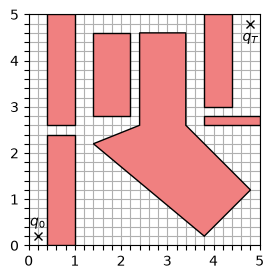

In [3]:
environment_setup()

for O in obstacles:
    plt.fill(*O.T, fc='lightcoral', ec='k', zorder=4)

plt.plot(*x_start, 'kx')
plt.plot(*x_goal, 'kx')

plt.text(.2, .35, '$q_0$', ha='center', va='bottom')
plt.text(4.8, 4.65, '$q_T$', ha='center', va='top')

if savefig:
    plt.savefig('setup.pdf', bbox_inches='tight')

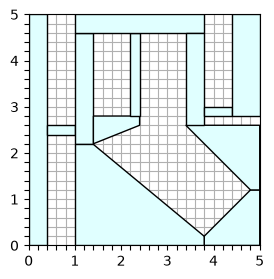

In [4]:
environment_setup()

for V in vertices:
    plt.fill(*V.T, fc='lightcyan', ec='k', zorder=4)

if savefig:
    plt.savefig('decomposition.pdf', bbox_inches='tight')

# Minimum-distance problem

In [5]:
def plot_trajectory(waypoints):

    plt.figure(figsize=(3, 3))

    for O in obstacles:
        plt.fill(*O.T, fc='lightcoral', ec='k', zorder=4)

    plt.plot(*x_start, 'kx')
    plt.plot(*x_goal, 'kx')
    plt.plot(*waypoints, 'b', zorder=5)

    plt.axis('square')
    plt.xlim([x_min[0], x_max[0]])
    plt.ylim([x_min[1], x_max[1]])
    plt.xticks(range(6))
    plt.yticks(range(6))
    plt.grid(1)

INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and no rounding.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and rounding.
INFO:drake:Found 2 unique paths, discarded 98 duplicate paths.
INFO:drake:Finished 2 rounding solutions with MOSEK.


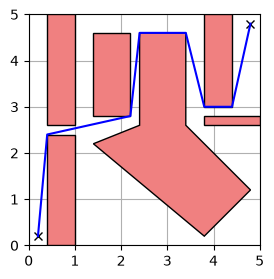

In [6]:
relaxation = True
gcs = LinearGCS(regions)
gcs.addSourceTarget(x_start, x_goal)
gcs.setSolver(MosekSolver())
waypoints = gcs.SolvePath(relaxation)[0]
plot_trajectory(waypoints)
if savefig:
    plt.savefig('linear.pdf', bbox_inches='tight')

# Minimum-time problem

In [7]:
qdot_min = -1
qdot_max = 1
n_samples = 500

def solve_bezier(order, continuity, regularizer=None, hdot_min=1e-6, velocity=None):
    
    gcs = BezierGCS(regions, order, continuity, hdot_min=hdot_min)

    gcs.addTimeCost(1)
    gcs.addVelocityLimits([qdot_min] * 2, [qdot_max] * 2)
    if regularizer is not None:
        gcs.addDerivativeRegularization(*regularizer, 2)
    gcs.addSourceTarget(x_start, x_goal, velocity=velocity)
    
    gcs.setSolver(MosekSolver())
    gcs.setPaperSolverOptions()
    
    traj = gcs.SolvePath(relaxation)[0]
    times = np.linspace(traj.start_time(), traj.end_time(), n_samples)
    waypoints = np.squeeze([traj.value(t) for t in times]).T
    velocities = np.squeeze([traj.EvalDerivative(t) for t in times]).T

    return waypoints, velocities, times

In [8]:
def plot_velocity(velocities, times, tol=np.inf):
    
    def plot_with_jumps(velocities, color):
        for i in range(len(times) - 1):
            dv = velocities[i + 1] - velocities[i]
            style = '-' if abs(dv) < tol else ':'
            plt.plot(times[i:i+2], velocities[i:i+2], color=color, linestyle=style)
            
    plt.figure(figsize=(3, 2))
            
    plot_with_jumps(velocities[0], 'tab:blue')
    plot_with_jumps(velocities[1], 'tab:orange')

    plt.xlim([times[0], times[-1]])
    plt.xticks(np.arange(int(np.ceil(times[-1] / 2))) * 2)
    plt.yticks(np.linspace(qdot_min, qdot_max, 5))
    plt.xlabel('Time $t$')
    plt.ylabel('Velocity $\dot{q}$')
    plt.grid()

<>:18: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:18: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
/tmp/ipykernel_1693/3165938659.py:18: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  plt.ylabel('Velocity $\dot{q}$')


INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and no rounding.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and rounding.
INFO:drake:Found 5 unique paths, discarded 95 duplicate paths.
INFO:drake:Finished 5 rounding solutions with MOSEK.


Problem
  Name                   :                 
  Objective sense        : minimize        
  Type                   : LO (linear optimization problem)
  Constraints            : 1541            
  Affine conic cons.     : 0               
  Disjunctive cons.      : 0               
  Cones                  : 0               
  Scalar variables       : 411             
  Matrix variables       : 0               
  Integer variables      : 0               

Optimizer started.
Presolve started.
Linear dependency checker started.
Linear dependency checker terminated.
Eliminator started.
Freed constraints in eliminator : 295
Eliminator terminated.
Eliminator started.
Freed constraints in eliminator : 21
Eliminator terminated.
Eliminator - tries                  : 2                 time                   : 0.00            
Lin. dep.  - tries                  : 1                 time                   : 0.00            
Lin. dep.  - primal attempts        : 1                 successes   

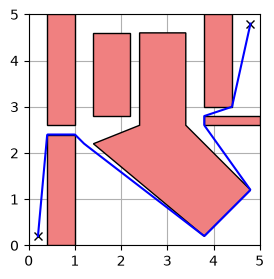

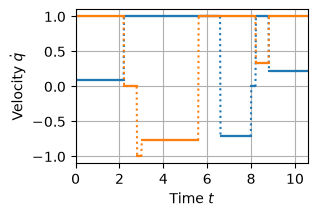

In [9]:
order = 1
continuity = 0
waypoints, velocities, times = solve_bezier(order, continuity)

plot_trajectory(waypoints)
if savefig:
    plt.savefig('bezier_10.pdf', bbox_inches='tight')

plot_velocity(velocities, times, tol=1e-1)
if savefig:
    plt.savefig('bezier_10_vel.pdf', bbox_inches='tight')

Problem
  Name                   :                 
  Objective sense        : minimize        
  Type                   : CONIC (conic optimization problem)
  Constraints            : 5558            
  Affine conic cons.     : 290 (1015 rows)
  Disjunctive cons.      : 0               
  Cones                  : 0               
  Scalar variables       : 1571            
  Matrix variables       : 0               
  Integer variables      : 0               

Optimizer started.
Presolve started.
Linear dependency checker started.
Linear dependency checker terminated.
Eliminator started.
Freed constraints in eliminator : 946
Eliminator terminated.
Eliminator started.
Freed constraints in eliminator : 123
Eliminator terminated.
Eliminator - tries                  : 2                 time                   : 0.00            
Lin. dep.  - tries                  : 1                 time                   : 0.00            
Lin. dep.  - primal attempts        : 1                 successes 

INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and no rounding.


16  1.9e-02  1.1e-01  1.5e-02  9.91e-01   3.078385920e+01   2.737227863e+01   1.9e-05  0.21  
17  6.7e-03  4.0e-02  3.1e-03  1.01e+00   2.766241501e+01   2.646342228e+01   6.7e-06  0.21  
18  4.6e-03  2.7e-02  1.8e-03  1.02e+00   2.713127402e+01   2.631068022e+01   4.6e-06  0.22  
19  4.5e-03  2.7e-02  1.8e-03  6.04e-01   2.718122084e+01   2.634023224e+01   4.5e-06  0.23  
20  4.4e-03  2.6e-02  1.7e-03  6.22e-01   2.718117486e+01   2.635099156e+01   4.3e-06  0.24  
21  4.0e-03  2.4e-02  1.6e-03  5.73e-01   2.720177514e+01   2.638940328e+01   4.0e-06  0.24  
22  3.6e-03  2.2e-02  1.4e-03  6.61e-01   2.713205536e+01   2.638666456e+01   3.6e-06  0.25  
23  2.8e-03  1.7e-02  1.0e-03  6.01e-01   2.703963435e+01   2.641101154e+01   2.8e-06  0.26  
24  2.0e-03  1.2e-02  6.5e-04  6.29e-01   2.692571517e+01   2.643841598e+01   2.0e-06  0.26  
25  1.6e-03  9.8e-03  5.1e-04  6.07e-01   2.689285884e+01   2.646565721e+01   1.6e-06  0.27  
26  1.3e-03  7.9e-03  4.0e-04  5.19e-01   2.688247842e+01   

INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and rounding.
INFO:drake:Found 4 unique paths, discarded 96 duplicate paths.
INFO:drake:Finished 4 rounding solutions with MOSEK.


30  3.8e-04  2.3e-03  9.6e-05  4.06e-01   2.696159803e+01   2.677997233e+01   3.8e-07  0.27  
31  2.3e-04  1.4e-03  5.0e-05  4.26e-01   2.702723950e+01   2.690207194e+01   2.3e-07  0.27  
32  1.6e-04  9.9e-04  3.3e-05  5.55e-01   2.706618711e+01   2.696802989e+01   1.7e-07  0.28  
33  1.3e-04  8.1e-04  2.6e-05  5.93e-01   2.709037951e+01   2.700593434e+01   1.4e-07  0.29  
34  8.6e-05  5.1e-04  1.4e-05  6.32e-01   2.713933026e+01   2.708092991e+01   8.6e-08  0.29  
35  6.0e-05  3.6e-04  8.5e-06  6.88e-01   2.717245514e+01   2.713040246e+01   6.0e-08  0.30  
36  2.7e-05  1.6e-04  2.8e-06  7.53e-01   2.722433748e+01   2.720427072e+01   2.7e-08  0.31  
37  1.5e-05  9.2e-05  1.3e-06  8.55e-01   2.724809576e+01   2.723623492e+01   1.5e-08  0.31  
38  5.7e-06  3.4e-05  3.0e-07  9.23e-01   2.727066420e+01   2.726615021e+01   5.7e-09  0.32  
39  2.4e-06  1.5e-05  8.8e-08  9.60e-01   2.727958932e+01   2.727763640e+01   2.4e-09  0.33  
40  8.7e-07  5.2e-06  2.0e-08  9.82e-01   2.728432665e+01   

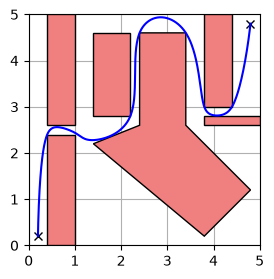

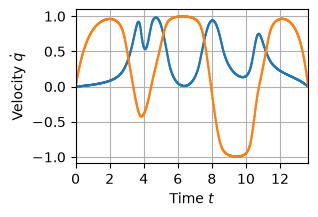

In [10]:
order = 6
continuity = 2
velocity = np.zeros((2, 2))
regularizer = [1e-1, 1e-1]
hdot_min = 1e-1
waypoints, velocities, times = solve_bezier(order, continuity, regularizer, hdot_min, velocity=velocity)

plot_trajectory(waypoints)
if savefig:
    plt.savefig('bezier_62.pdf', bbox_inches='tight')

plot_velocity(velocities, times)
if savefig:
    plt.savefig('bezier_62_vel.pdf', bbox_inches='tight')

INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and no rounding.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and rounding.
INFO:drake:Found 1 unique paths, discarded 99 duplicate paths.
INFO:drake:Finished 1 rounding solutions with MOSEK.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and no rounding.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and rounding.
INFO:drake:Found 5 unique paths, discarded 95 duplicate paths.
INFO:drake:Finished 5 rounding solutions with MOSEK.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and no rounding.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and rounding.
INFO:drake:Found 1 unique paths, discarded 99 duplicate paths.
INFO:drake:F

Temps séquentiel (avec arrêts) : 18.34 s | t_wp=[np.float64(6.3), np.float64(12.51)]
Temps Fly-by exact (eps=0.00)  : 19.15 s | gap=6.62% | t_wp=[5.96, 13.32]
Temps Fly-by toléré (eps=0.25) : 17.33 s | gap=6.53% | t_wp=[5.81, 11.39]


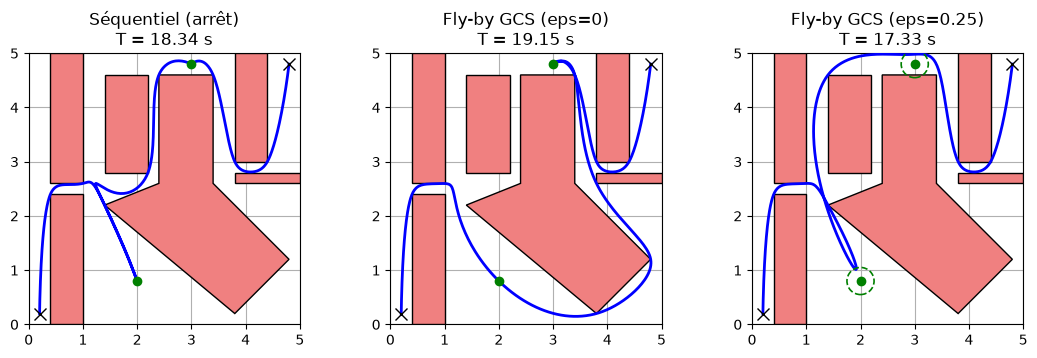

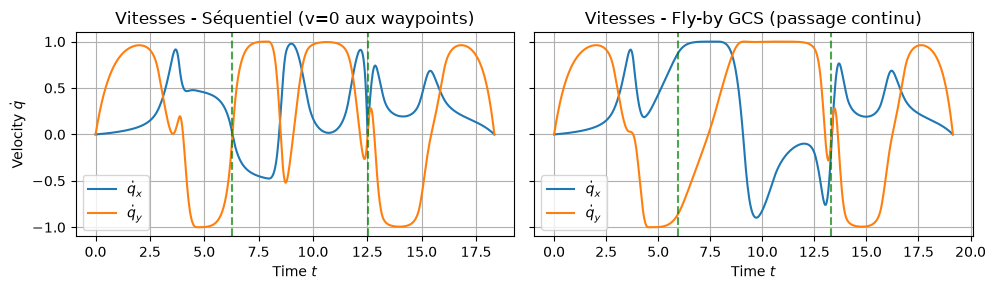

In [13]:
from pydrake.solvers import CommonSolverOption

# Waypoints garantis dans l'espace libre (Figure 2b)
waypoints_list = [
    np.array([2.0, 0.8]),  # Bas-centre (sous l'obstacle central)
    np.array([3.0, 4.8]),  # Couloir supérieur (au-dessus de l'obstacle central)
]

# Vérification rapide que chaque waypoint appartient bien à au moins une région libre
for k, wp in enumerate(waypoints_list):
    assert any(r.PointInSet(wp) for r in regions), f"Waypoint {k} ({wp}) est dans un obstacle !"

order = 6
continuity = 2
velocity = np.zeros((2, 2))
regularizer = [1e-1, 1e-1]
hdot_min = 1e-1

def configure_solver(gcs_obj, print_console=False):
    gcs_obj.setSolver(MosekSolver())
    gcs_obj.setPaperSolverOptions()
    if not print_console:
        gcs_obj.options.solver_options.SetOption(CommonSolverOption.kPrintToConsole, 0)

# 1) Baseline : 3 appels séparés avec arrêt complet (v=0) à chaque waypoint
all_pts = [x_start] + waypoints_list + [x_goal]
seq_total_time = 0.0
seq_pos, seq_vel, seq_t, seq_wp_times = [], [], [], []
for idx, (p0, p1) in enumerate(zip(all_pts[:-1], all_pts[1:])):
    g_seq = BezierGCS(regions, order, continuity, hdot_min=hdot_min)
    g_seq.addTimeCost(1)
    g_seq.addVelocityLimits([qdot_min] * 2, [qdot_max] * 2)
    g_seq.addDerivativeRegularization(*regularizer, 2)
    g_seq.addSourceTarget(p0, p1, velocity=np.zeros((2, 2)))
    configure_solver(g_seq)
    tr, _ = g_seq.SolvePath(rounding=True)
    ts = np.linspace(tr.start_time(), tr.end_time(), 200)
    seq_pos.append(np.squeeze([tr.value(t) for t in ts]).T)
    seq_vel.append(np.squeeze([tr.EvalDerivative(t) for t in ts]).T)
    seq_t.append(ts + seq_total_time)
    seq_total_time += tr.end_time()
    if idx < len(waypoints_list):
        seq_wp_times.append(seq_total_time)

seq_pos = np.hstack(seq_pos)
seq_vel = np.hstack(seq_vel)
seq_t = np.concatenate(seq_t)

# 2) Extension 1 : Fly-by exact (epsilon = 0.0) en un seul SOCP
g_fly = BezierGCS(
    regions, order, continuity, hdot_min=hdot_min,
    waypoints=waypoints_list, waypoint_radii=0.0
)
g_fly.addTimeCost(1)
g_fly.addVelocityLimits([qdot_min] * 2, [qdot_max] * 2)
g_fly.addDerivativeRegularization(*regularizer, 2)
g_fly.addSourceTarget(x_start, x_goal, velocity=velocity)
configure_solver(g_fly)
traj_fly, res_fly = g_fly.SolvePath(rounding=True)

times_fly = np.linspace(traj_fly.start_time(), traj_fly.end_time(), n_samples)
pos_fly = np.squeeze([traj_fly.value(t) for t in times_fly]).T
vel_fly = np.squeeze([traj_fly.EvalDerivative(t) for t in times_fly]).T

# 3) Extension 1 : Fly-by avec boule de tolérance (epsilon = 0.25)
eps = 0.25
g_tol = BezierGCS(
    regions, order, continuity, hdot_min=hdot_min,
    waypoints=waypoints_list, waypoint_radii=eps
)
g_tol.addTimeCost(1)
g_tol.addVelocityLimits([qdot_min] * 2, [qdot_max] * 2)
g_tol.addDerivativeRegularization(*regularizer, 2)
g_tol.addSourceTarget(x_start, x_goal, velocity=velocity)
configure_solver(g_tol)
traj_tol, res_tol = g_tol.SolvePath(rounding=True)

times_tol = np.linspace(traj_tol.start_time(), traj_tol.end_time(), n_samples)
pos_tol = np.squeeze([traj_tol.value(t) for t in times_tol]).T
vel_tol = np.squeeze([traj_tol.EvalDerivative(t) for t in times_tol]).T

print(f"Temps séquentiel (avec arrêts) : {seq_total_time:.2f} s | t_wp={[round(t, 2) for t in seq_wp_times]}")
print(f"Temps Fly-by exact (eps=0.00)  : {traj_fly.end_time():.2f} s | gap={100*res_fly['certified_gap']:.2f}% | t_wp={[round(t, 2) for t in res_fly['waypoint_times']]}")
print(f"Temps Fly-by toléré (eps={eps}) : {traj_tol.end_time():.2f} s | gap={100*res_tol['certified_gap']:.2f}% | t_wp={[round(t, 2) for t in res_tol['waypoint_times']]}")

# --- Affichage comparatif des trajectoires ---
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
configs = [
    (axes[0], seq_pos, f"Séquentiel (arrêt)\nT = {seq_total_time:.2f} s", False),
    (axes[1], pos_fly, f"Fly-by GCS (eps=0)\nT = {traj_fly.end_time():.2f} s", False),
    (axes[2], pos_tol, f"Fly-by GCS (eps={eps})\nT = {traj_tol.end_time():.2f} s", True),
]
for ax, pos, title, draw_circle in configs:
    for O in obstacles:
        ax.fill(*O.T, fc='lightcoral', ec='k', zorder=4)
    ax.plot(*x_start, 'kx', markersize=8, zorder=6)
    ax.plot(*x_goal, 'kx', markersize=8, zorder=6)
    for wp in waypoints_list:
        ax.plot(*wp, 'go', markersize=6, zorder=6)
        if draw_circle:
            ax.add_patch(plt.Circle(wp, eps, color='green', fill=False, ls='--', lw=1.2, zorder=6))
    ax.plot(*pos, 'b', lw=2, zorder=5)
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.set_xlim([x_min[0], x_max[0]])
    ax.set_ylim([x_min[1], x_max[1]])
    ax.grid(True)
plt.tight_layout()
plt.show()

# --- Affichage comparatif des profils de vitesse ---
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, vel, ts, wpt, title in [
    (axes[0], seq_vel, seq_t, seq_wp_times, "Vitesses - Séquentiel (v=0 aux waypoints)"),
    (axes[1], vel_fly, times_fly, res_fly["waypoint_times"], "Vitesses - Fly-by GCS (passage continu)"),
]:
    ax.plot(ts, vel[0], label=r"$\dot{q}_x$")
    ax.plot(ts, vel[1], label=r"$\dot{q}_y$")
    for t_w in wpt:
        ax.axvline(t_w, color='g', ls='--', alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("Time $t$")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel(r"Velocity $\dot{q}$")
plt.tight_layout()
plt.show()

In [14]:
# 1) Comparaison des COÛTS TOTAUX J (Temps + Régularisation) sur le run précédent
# (Recalcul rapide du coût séquentiel C1 vs C2 strict avec zero_deriv_boundary=2)
def run_sequential(order, continuity, zero_deriv_boundary=None):
    all_pts = [x_start] + waypoints_list + [x_goal]
    total_T, total_J = 0.0, 0.0
    for p0, p1 in zip(all_pts[:-1], all_pts[1:]):
        g = BezierGCS(regions, order, continuity, hdot_min=hdot_min)
        g.addTimeCost(1)
        g.addVelocityLimits([qdot_min] * 2, [qdot_max] * 2)
        g.addDerivativeRegularization(*regularizer, 2)
        if zero_deriv_boundary is not None:
            g.addSourceTarget(p0, p1, zero_deriv_boundary=zero_deriv_boundary)
        else:
            g.addSourceTarget(p0, p1, velocity=np.zeros((2, 2)))
        configure_solver(g)
        tr, res = g.SolvePath(rounding=True)
        total_T += tr.end_time()
        total_J += res["rounded_cost"]
    return total_T, total_J

T_seq_c1, J_seq_c1 = run_sequential(order=6, continuity=2, zero_deriv_boundary=None)
T_seq_c2, J_seq_c2 = run_sequential(order=6, continuity=2, zero_deriv_boundary=2)

print("=== Comparaison équitable (order=6, continuity=2) ===")
print(f"Séquentiel (C1 aux wp, saut d'accél.) : T = {T_seq_c1:.2f} s | Coût total J = {J_seq_c1:.2f}")
print(f"Séquentiel strict (C2 aux wp, a=0)    : T = {T_seq_c2:.2f} s | Coût total J = {J_seq_c2:.2f}")
print(f"Fly-by exact (eps=0.00, C2 partout)   : T = {traj_fly.end_time():.2f} s | Coût total J = {res_fly['rounded_cost']:.2f}")
print(f"Fly-by toléré (eps=0.25, C2 partout)  : T = {traj_tol.end_time():.2f} s | Coût total J = {res_tol['rounded_cost']:.2f}")

INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and no rounding.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and rounding.
INFO:drake:Found 1 unique paths, discarded 99 duplicate paths.
INFO:drake:Finished 1 rounding solutions with MOSEK.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and no rounding.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and rounding.
INFO:drake:Found 5 unique paths, discarded 95 duplicate paths.
INFO:drake:Finished 5 rounding solutions with MOSEK.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and no rounding.
INFO:drake:Solved GCS shortest path using MOSEK with convex_relaxation=true and preprocessing=false and rounding.
INFO:drake:Found 1 unique paths, discarded 99 duplicate paths.
INFO:drake:F

=== Comparaison équitable (order=6, continuity=2) ===
Séquentiel (C1 aux wp, saut d'accél.) : T = 18.34 s | Coût total J = 37.86
Séquentiel strict (C2 aux wp, a=0)    : T = 21.17 s | Coût total J = 58.80
Fly-by exact (eps=0.00, C2 partout)   : T = 19.15 s | Coût total J = 35.84
Fly-by toléré (eps=0.25, C2 partout)  : T = 17.33 s | Coût total J = 33.97
